# 01 — Candidate sample, magnitude cuts and expected Gaia testability

This notebook summarises `data/candidates.csv` and the pre-registration inputs in
`results/frozen/`. **No Gaia epoch photometry is used**: the Gaia magnitude is the DR3 mean
`phot_g_mean_mag` (used only for the G < 20.7 cut), and Gaia cadences are *mock* cadences.
Power numbers are therefore planning estimates; the binding testability rule is evaluated on
the real DR4 timestamps after release (see `preregistration/prereg.md`).

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '../src')
import config as C
pd.set_option('display.width', 160)
cand = pd.read_csv(C.CANDIDATES_CSV)
dr3 = pd.read_csv(C.RAW / 'dr3_mean_g.csv')
cand = cand.merge(dr3, on='cand_id', how='left')
fr = C.RESULTS / 'frozen'
summ = pd.read_csv(fr / 'discovery_summary.csv')
power = pd.read_csv(fr / 'power_mock.csv')
params = pd.read_csv(fr / 'frozen_params.csv')
len(cand)

447

## Candidates per sample, and how many pass G < 20.7 (DR3 mean G)

In [2]:
cand['G_lt_20p7'] = cand['dr3_g_mean'] < C.GAIA_G_LIMIT
cand['has_dr3'] = cand['dr3_status'] == 'ok'
t = cand.groupby('sample').agg(n=('cand_id','size'), final=('in_final_sample','sum'),
                               dr3_match=('has_dr3','sum'), G_lt_20p7=('G_lt_20p7','sum'))
t

,n,final,dr3_match,G_lt_20p7
sample,,,,
Charisi2016,50,33,50,49
Chen2024,3,3,3,3
Foustoul2025,257,36,254,243
Graham2015,111,111,111,111
Liu2019,26,1,26,26


In [3]:
fin = cand[(cand['sample']!='Charisi2016') | cand['in_final_sample']]
fin.groupby('sample')['G_lt_20p7'].agg(['size','sum'])

,size,sum
sample,,
Charisi2016,33,33
Chen2024,3,3
Foustoul2025,257,243
Graham2015,111,111
Liu2019,26,26


## Why candidates drop out before scoring

In [4]:
summ.groupby(['sample','status']).size().unstack(fill_value=0).T

sample,Charisi2016,Chen2024,Foustoul2025,Graham2015,Liu2019
status,,,,,
CRTS light curve unavailable (used by Foustoul),0,0,170,0,0
G cut (DR3 mean G = 20.711626052856445),0,0,1,0,0
G cut (DR3 mean G = 20.72633934020996),0,0,1,0,0
G cut (DR3 mean G = 20.737625122070312),0,0,1,0,0
G cut (DR3 mean G = 20.757251739501953),0,0,1,0,0
G cut (DR3 mean G = 20.781808853149414),0,0,1,0,0
G cut (DR3 mean G = 20.791913986206055),0,0,1,0,0
G cut (DR3 mean G = 20.811927795410156),0,0,1,0,0
G cut (DR3 mean G = 20.955568313598633),0,0,1,0,0


## Survey magnitude vs Gaia DR3 mean G

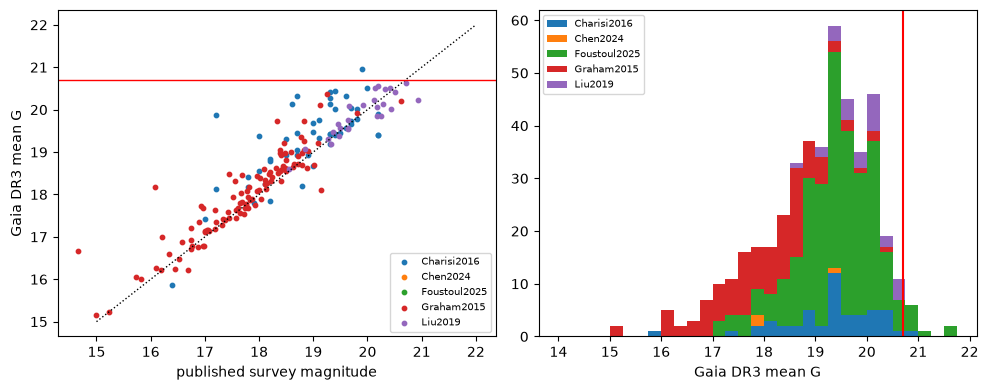

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for s, g in cand.groupby('sample'):
    ax[0].scatter(g['mag'], g['dr3_g_mean'], s=10, label=s)
ax[0].plot([15, 22], [15, 22], 'k:', lw=1); ax[0].axhline(C.GAIA_G_LIMIT, color='r', lw=1)
ax[0].set_xlabel('published survey magnitude'); ax[0].set_ylabel('Gaia DR3 mean G'); ax[0].legend(fontsize=7)
ax[1].hist([g['dr3_g_mean'].dropna() for _, g in cand.groupby('sample')], bins=np.arange(14, 22, 0.25),
           stacked=True, label=list(cand.groupby('sample').groups))
ax[1].axvline(C.GAIA_G_LIMIT, color='r'); ax[1].set_xlabel('Gaia DR3 mean G'); ax[1].legend(fontsize=7)
plt.tight_layout()

## Expected power on the mock DR4 cadence

In [6]:
pw = power.merge(params[['cand_id','period_d','sin_semi_amp','D_sigma','test_win_lo','test_win_hi','dr3_g_mean']], on='cand_id')
pw['cycles_in_window'] = (pw.test_win_hi - pw.test_win_lo) / pw.period_d
pw.groupby('sample')[['power_p05','power_lnB3','null_frac_lnB3']].describe().T.round(3)

sample                Charisi2016  Foustoul2025  Graham2015
power_p05      count       33.000        73.000      75.000
               mean         0.844         0.297       0.792
               std          0.167         0.143       0.206
               min          0.402         0.126       0.261
               25%          0.716         0.202       0.651
               50%          0.913         0.268       0.861
               75%          0.985         0.324       0.974
               max          1.000         0.822       1.000
power_lnB3     count       33.000        73.000      75.000
               mean         0.706         0.056       0.585
               std          0.238         0.097       0.285
               min          0.160         0.000       0.017
               25%          0.518         0.006       0.344
               50%          0.774         0.025       0.630
               75%          0.898         0.046       0.831
               max          0.997         0.500       0.993
null_frac_lnB3 count       33.000        73.000      75.000
               mean         0.002         0.001       0.004
               std          0.002         0.002       0.003
               min          0.000         0.000       0.000
               25%          0.001         0.000       0.002
               50%          0.002         0.000       0.004
               75%          0.004         0.002       0.006
               max          0.007         0.011       0.010

In [7]:
rules = {'power(p<0.05) >= 0.5': pw.power_p05 >= 0.5,
         'power(p<0.05) >= 0.8': pw.power_p05 >= 0.8,
         'P(lnB>3 | S) >= 0.8': pw.power_lnB3 >= 0.8,
         'P(lnB>3 | S) >= 0.5': pw.power_lnB3 >= 0.5}
pd.DataFrame({k: pw[v].groupby('sample').size() for k, v in rules.items()}).fillna(0).astype(int)

,power(p<0.05) >= 0.5,power(p<0.05) >= 0.8,P(lnB>3 | S) >= 0.8,P(lnB>3 | S) >= 0.5
sample,,,,
Charisi2016,31,22,16,25
Foustoul2025,7,1,0,1
Graham2015,66,46,24,47


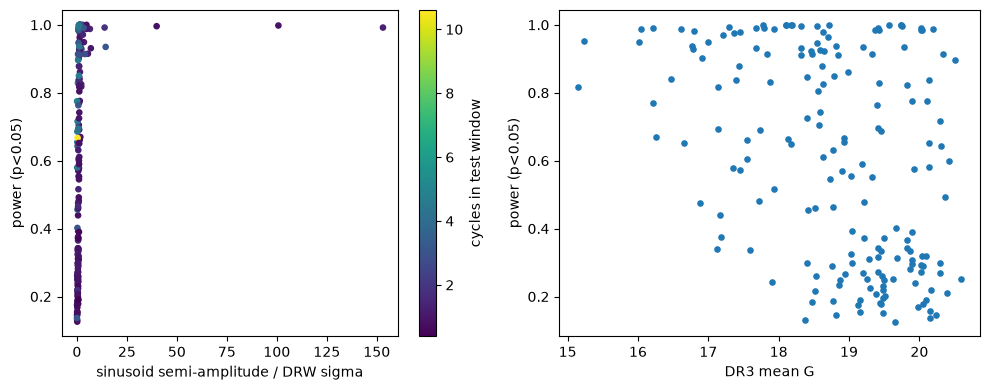

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sc = ax[0].scatter(pw.sin_semi_amp / pw.D_sigma, pw.power_p05, c=pw.cycles_in_window, s=14)
plt.colorbar(sc, ax=ax[0], label='cycles in test window')
ax[0].set_xlabel('sinusoid semi-amplitude / DRW sigma'); ax[0].set_ylabel('power (p<0.05)')
ax[1].scatter(pw.dr3_g_mean, pw.power_p05, s=14); ax[1].set_xlabel('DR3 mean G'); ax[1].set_ylabel('power (p<0.05)')
plt.tight_layout()

## Notes
* Phases/T0 are not published by any source paper; Graham+2015 and Charisi+2016 publish no
  period errors. The frozen sinusoid phase and amplitude come from the discovery data only.
* The mock cadence (`src/gaia.py::mock_cadence`) is a planning assumption.